# 06 · Points of interest and critical facilities

Overture POIs at tract level: counts and rates, what they scale with, their quality fields, and the fire, EMS, school and hospital facilities the POI component is built on.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. How many POIs, and how dense?

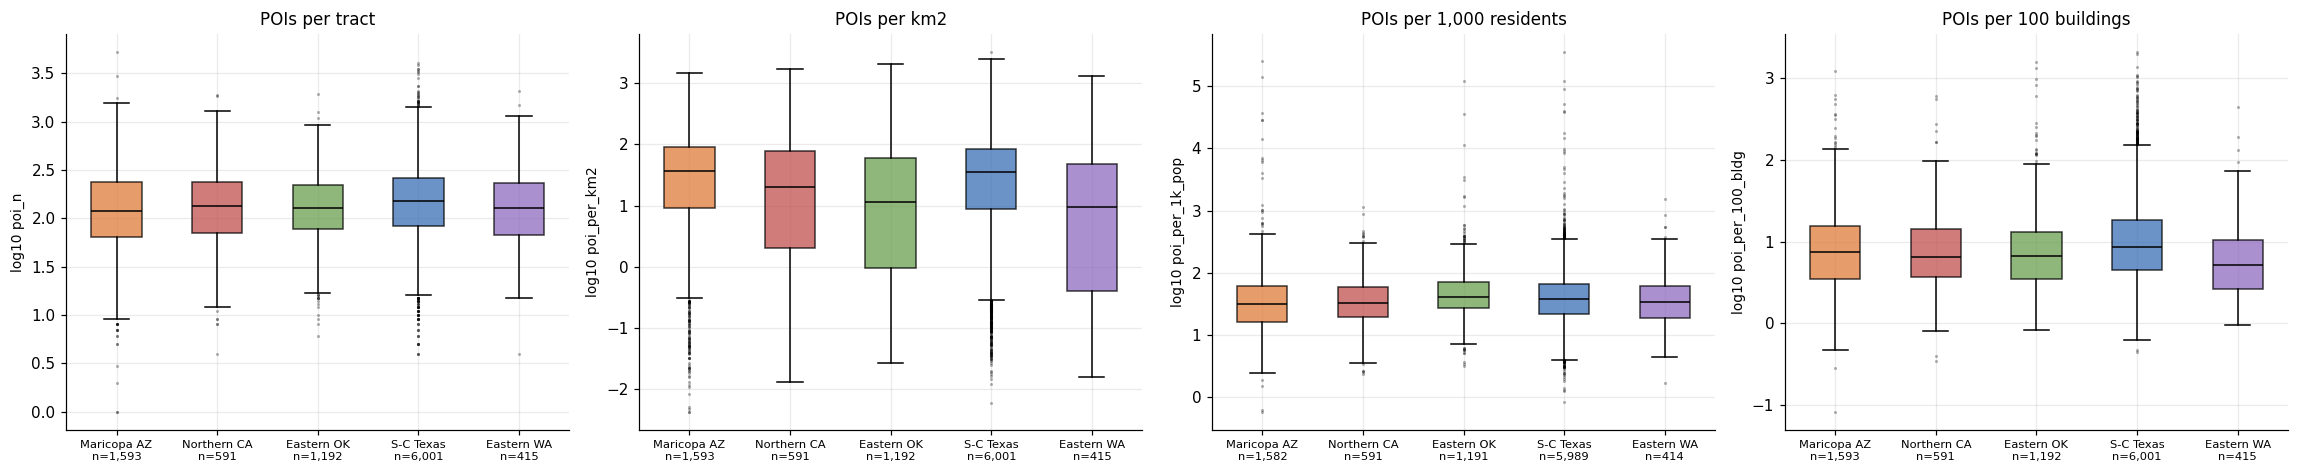

                  poi_n  poi_per_km2  poi_per_1k_pop  poi_per_100_bldg
region                                                                
maricopa-az       120.0         37.3            31.4               7.4
northern-ca       134.0         19.9            33.1               6.4
eastern-ok        128.0         11.5            40.3               6.6
south-central-tx  151.0         35.5            37.2               8.6
eastern-wa        129.0          9.6            34.3               5.1

total POIs: 2,001,075 | Texas share: 65.0% | tracts with 0 POIs: 2


In [2]:
fig, ax = plt.subplots(1, 4, figsize=(21, 4.4)); box_by_region(ax[0], "poi_n", log=True, title="POIs per tract"); box_by_region(ax[1], "poi_per_km2", log=True, title="POIs per km2"); box_by_region(ax[2], "poi_per_1k_pop", log=True, title="POIs per 1,000 residents"); box_by_region(ax[3], "poi_per_100_bldg", log=True, title="POIs per 100 buildings")
plt.tight_layout(); plt.show(); print(df.groupby("region")[["poi_n", "poi_per_km2", "poi_per_1k_pop", "poi_per_100_bldg"]].median().reindex(REG).round(1).to_string()); print("\ntotal POIs:", f"{int(df.poi_n.sum()):,}", "| Texas share:", f"{df[df.region == 'south-central-tx'].poi_n.sum() / df.poi_n.sum():.1%}", "| tracts with 0 POIs:", int((df.poi_n == 0).sum()))

**Takeaway:** there are 2.0 million POIs, 65% of them in Texas. The typical tract has 120-151 POIs in every region, so counts are strikingly similar across very different places. Rates differ more: POIs per km2 run from 9.6 (Eastern WA) to 37 (Maricopa), and POIs per 100 buildings from 5.1 to 8.6. Only 2 tracts (the all-water ones) have none.

## 2. Do POIs scale with people, land or buildings?

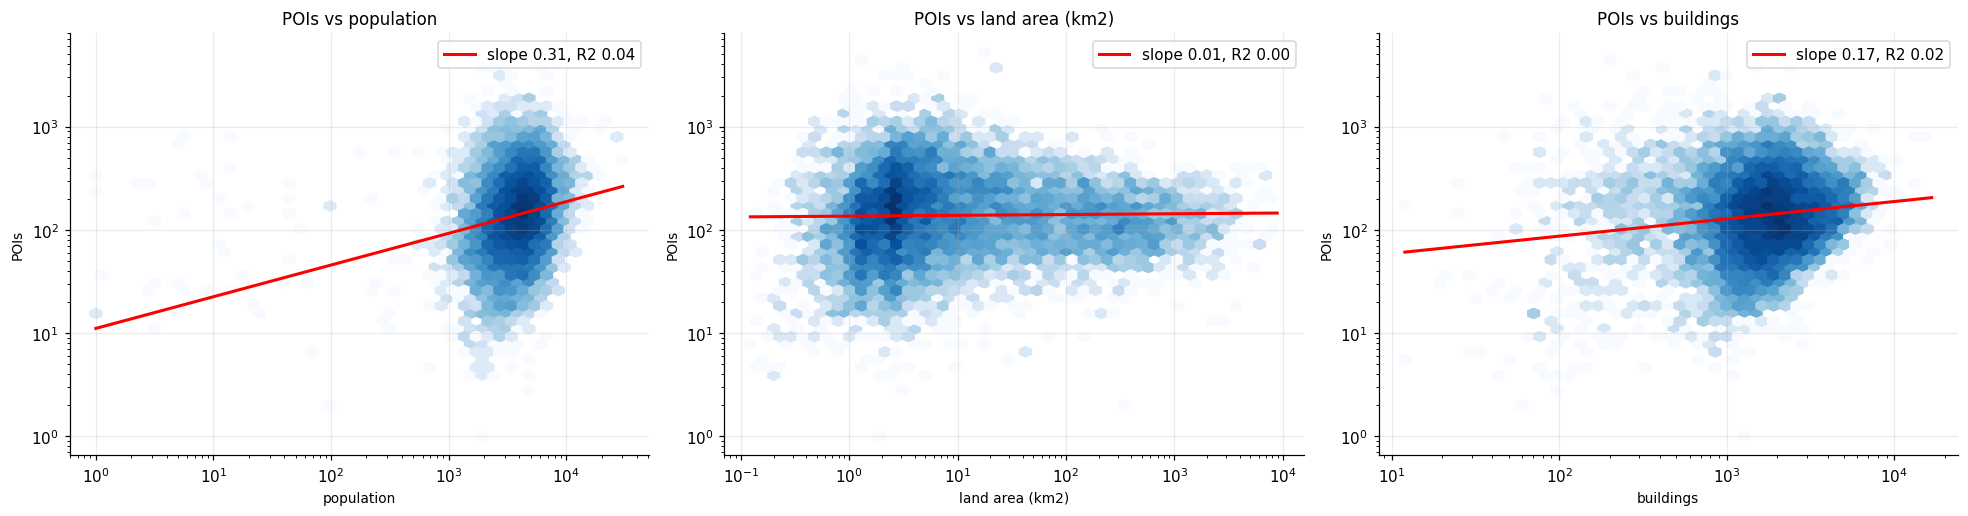

         driver  log-log slope   R2  Spearman
     population           0.31 0.04      0.23
land area (km2)           0.01 0.00      0.06
      buildings           0.17 0.02      0.12


In [3]:
d = df[(df.poi_n > 0) & (df.pop_total > 0) & (df.land_km2 > 0) & (df.bldg_n > 0)]; fig, ax = plt.subplots(1, 3, figsize=(18, 4.8)); rows = []
for a, (c, nm) in zip(ax, [("pop_total", "population"), ("land_km2", "land area (km2)"), ("bldg_n", "buildings")]):
    lx, ly = np.log10(d[c]), np.log10(d.poi_n); sl, ic, rr, p, se = stats.linregress(lx, ly); a.hexbin(d[c], d.poi_n, gridsize=45, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log")
    xs = np.linspace(lx.min(), lx.max(), 50); a.plot(10 ** xs, 10 ** (ic + sl * xs), "r", lw=2, label=f"slope {sl:.2f}, R2 {rr ** 2:.2f}"); a.set(xlabel=nm, ylabel="POIs", title=f"POIs vs {nm}"); a.legend(); rows.append((nm, sl, rr ** 2, stats.spearmanr(d[c], d.poi_n)[0]))
plt.tight_layout(); plt.show(); print(pd.DataFrame(rows, columns=["driver", "log-log slope", "R2", "Spearman"]).round(2).to_string(index=False))

**Takeaway:** POI counts barely depend on tract size. Against land area the log-log slope is 0.01 (R2 0.00), against population 0.31 (R2 0.04) and against buildings 0.17 (R2 0.02). Tracts are drawn around equal populations, and places do not follow people tightly, so POIs per building or per resident are driven by the denominator, not the numerator. This is why POIs per 100 buildings is noisy and why POI counts alone predict little.

## 3. POI quality: confidence, open status, categories

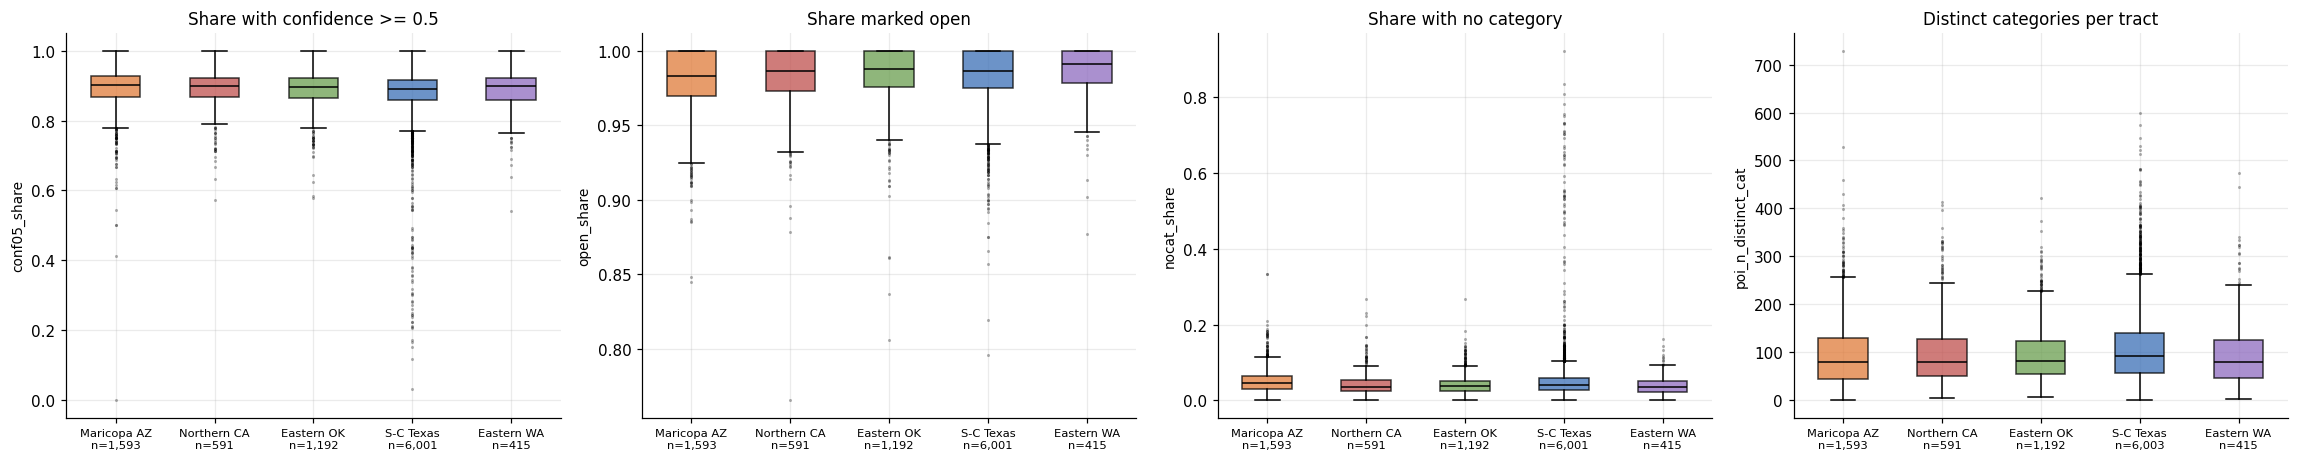

                  conf05_share  open_share  nocat_share  poi_n_distinct_cat
region                                                                     
maricopa-az              0.902       0.983        0.046                79.0
northern-ca              0.900       0.987        0.036                80.0
eastern-ok               0.897       0.988        0.036                82.0
south-central-tx         0.891       0.986        0.040                92.0
eastern-wa               0.898       0.991        0.035                79.0


In [4]:
df["open_share"] = df.poi_n_open / df.poi_n.replace(0, np.nan); df["nocat_share"] = df.poi_n_nocat / df.poi_n.replace(0, np.nan)
fig, ax = plt.subplots(1, 4, figsize=(21, 4.3)); box_by_region(ax[0], "conf05_share", title="Share with confidence >= 0.5"); box_by_region(ax[1], "open_share", title="Share marked open"); box_by_region(ax[2], "nocat_share", title="Share with no category"); box_by_region(ax[3], "poi_n_distinct_cat", title="Distinct categories per tract")
plt.tight_layout(); plt.show(); print(df.groupby("region")[["conf05_share", "open_share", "nocat_share", "poi_n_distinct_cat"]].median().reindex(REG).round(3).to_string())

**Takeaway:** POI quality fields look uniform across regions: about 90% of POIs have confidence of at least 0.5, 98-99% are marked open and 3.5-4.6% have no category. Texas has more distinct categories per tract (median 92 vs 79-82).

## 4. Critical facilities: fire, EMS, schools, hospitals
These are the facility types the POI component is built on, so their presence and scarcity matters.

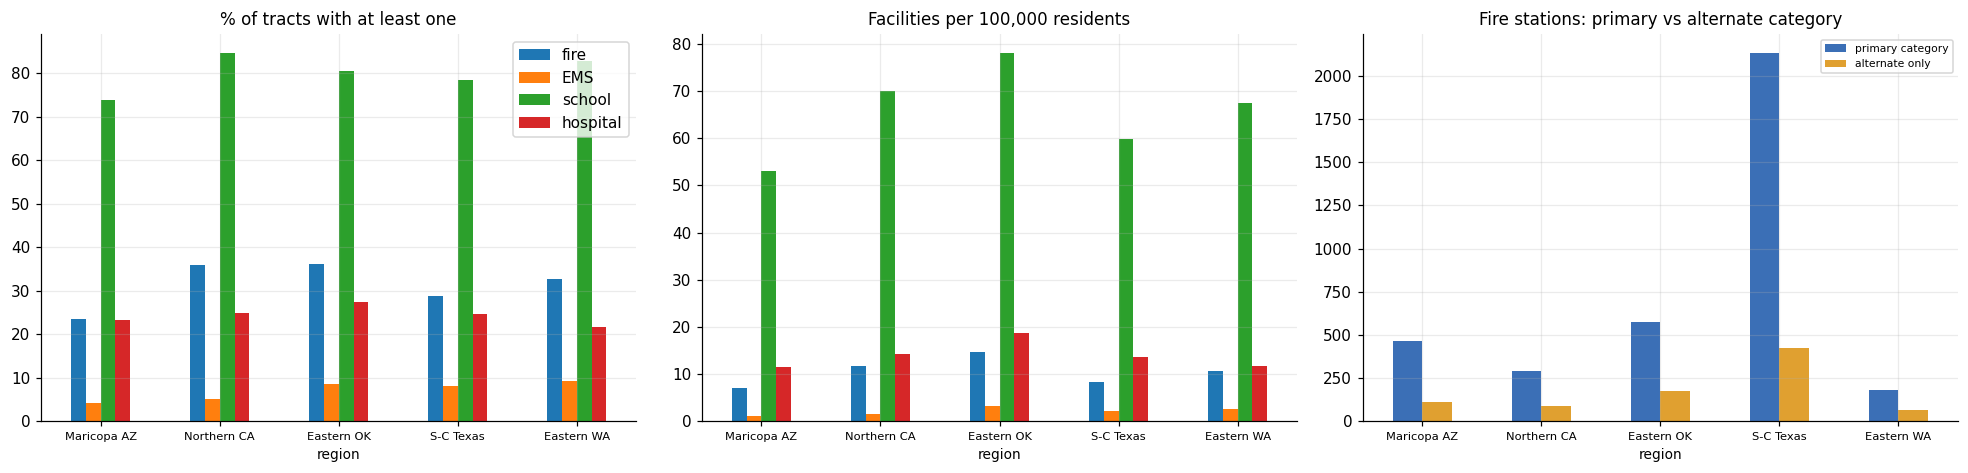

                  fire  EMS  school  hospital
region                                       
maricopa-az       23.4  4.1    73.9      23.2
northern-ca       35.9  5.1    84.8      24.9
eastern-ok        36.2  8.6    80.5      27.5
south-central-tx  28.8  8.0    78.5      24.6
eastern-wa        32.8  9.2    82.9      21.7

                  fire  EMS  school  hospital
region                                       
maricopa-az        7.0  1.1    53.0      11.5
northern-ca       11.8  1.5    70.1      14.2
eastern-ok        14.7  3.1    78.2      18.7
south-central-tx   8.3  2.2    59.9      13.7
eastern-wa        10.7  2.6    67.4      11.7

totals: {'poi_n_fire': 3641, 'poi_n_ems': 837, 'poi_n_school': 24854, 'poi_n_hospital': 5561} | fire alt: 867


In [5]:
fac = {"fire": "poi_n_fire", "EMS": "poi_n_ems", "school": "poi_n_school", "hospital": "poi_n_hospital"}
pres = pd.DataFrame({k: df.groupby("region")[c].apply(lambda s: (s > 0).mean()) for k, c in fac.items()}).reindex(REG)
per = df.groupby("region")[list(fac.values())].sum().reindex(REG).div(df.groupby("region").pop_total.sum().reindex(REG), axis=0) * 1e5; per.columns = fac.keys()
alt = df.groupby("region")[["poi_n_fire", "poi_n_fire_alt"]].sum().reindex(REG)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4)); (pres * 100).plot.bar(ax=ax[0], rot=0); ax[0].set_title("% of tracts with at least one"); per.plot.bar(ax=ax[1], rot=0, legend=False); ax[1].set_title("Facilities per 100,000 residents")
alt.plot.bar(ax=ax[2], rot=0, color=["#3b6fb6", "#e0a030"]); ax[2].set_title("Fire stations: primary vs alternate category"); ax[2].legend(["primary category", "alternate only"], fontsize=7)
for a in ax: a.set_xticklabels([NAME[r] for r in REG], fontsize=7.5)
plt.tight_layout(); plt.show(); print((pres * 100).round(1).to_string()); print(); print(per.round(1).to_string()); print("\ntotals:", df[list(fac.values())].sum().astype(int).to_dict(), "| fire alt:", int(df.poi_n_fire_alt.sum()))

**Takeaway:** critical facilities are rare and lumpy. A fire-department POI exists in only 23% (Maricopa) to 36% (Eastern OK) of tracts and an EMS POI in 4% to 9%, versus 74-85% for schools and 22-28% for hospitals. Per 100,000 residents Maricopa has the fewest fire stations (7.0) and Eastern OK the most (14.7). Overall there are 3,641 fire, 837 EMS, 24,854 school and 5,561 hospital POIs, plus 867 fire stations listed only under an alternate category, which the target's primary-category rule would not count.

## 5. What goes with having a fire POI?

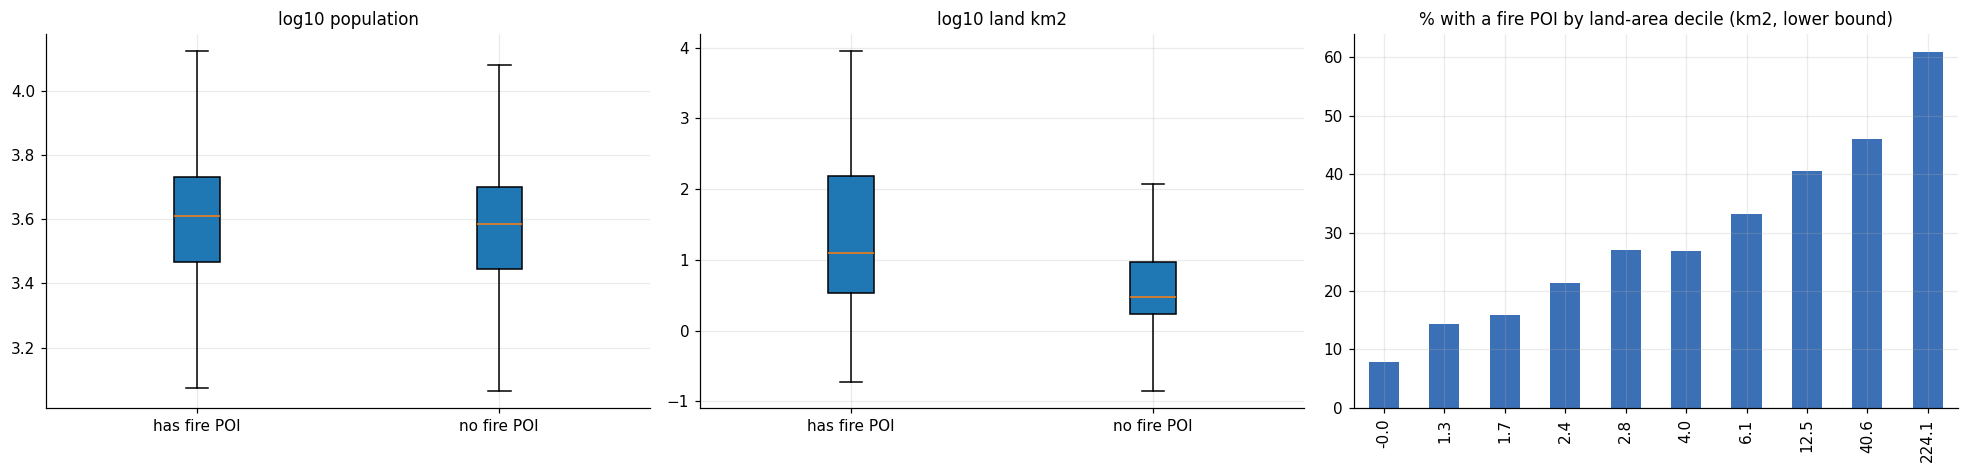

point-biserial: fire presence vs log population 0.032 | vs log land 0.332
% with fire POI, urban vs rural: {'Rural': 54.3, 'Urban': 23.6}
fire POIs per tract: {0.0: 6912, 1.0: 2293, 2.0: 464, 3.0: 89, 4.0: 28, 5.0: 7, 6.0: 1}


In [6]:
df["has_fire"] = df.poi_n_fire > 0; fig, ax = plt.subplots(1, 3, figsize=(18, 4.4))
for a, (c, nm) in zip(ax[:2], [("pop_total", "log10 population"), ("land_km2", "log10 land km2")]):
    a.boxplot([np.log10(df.loc[df.has_fire == v, c].clip(lower=.01)) for v in (True, False)], patch_artist=True, showfliers=False); a.set_xticklabels(["has fire POI", "no fire POI"]); a.set_title(nm)
q = pd.qcut(df.land_km2, 10, duplicates="drop"); rate = df.groupby(q).has_fire.mean() * 100; rate.index = [f"{i.left:.1f}" for i in rate.index]; rate.plot.bar(ax=ax[2], color="#3b6fb6"); ax[2].set_title("% with a fire POI by land-area decile (km2, lower bound)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()
print("point-biserial: fire presence vs log population", round(stats.pointbiserialr(df.has_fire, np.log10(df.pop_total.clip(lower=1)))[0], 3), "| vs log land", round(stats.pointbiserialr(df.has_fire, np.log10(df.land_km2.clip(lower=.01)))[0], 3))
print("% with fire POI, urban vs rural:", (df.groupby("ur_class").has_fire.mean() * 100).round(1).to_dict()); print("fire POIs per tract:", df.poi_n_fire.value_counts().sort_index().to_dict())

**Takeaway:** having a fire POI depends on tract *area*, not population: the point-biserial correlation is 0.33 with log land area and 0.03 with log population. Rural tracts are therefore more likely to contain one (54% vs 24% of urban tracts), most likely because they are bigger. Only 29% of tracts have any fire POI, and 6,912 have none.

## 6. Map of POI coverage

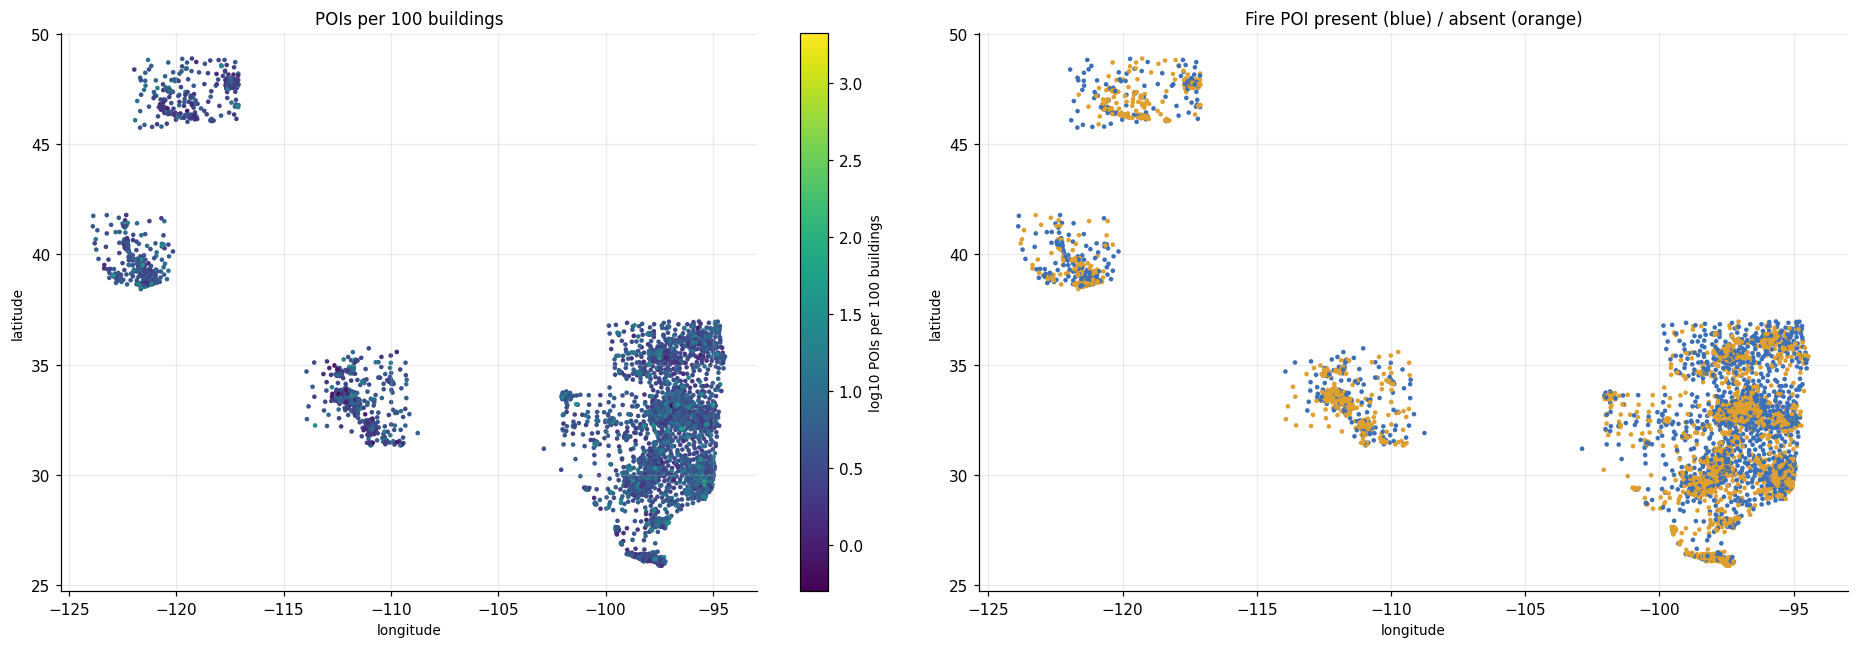

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sc = ax[0].scatter(df.INTPTLON, df.INTPTLAT, c=np.log10(df.poi_per_100_bldg.clip(lower=.5)), s=4, cmap="viridis"); plt.colorbar(sc, ax=ax[0], label="log10 POIs per 100 buildings"); ax[0].set_title("POIs per 100 buildings")
ax[1].scatter(df.INTPTLON, df.INTPTLAT, c=np.where(df.has_fire, "#3b6fb6", "#e0a030"), s=4); ax[1].set_title("Fire POI present (blue) / absent (orange)")
for a in ax: a.set(xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.show()

**Takeaway:** POIs per 100 buildings shows no strong geographic pattern (mostly low values everywhere, with the Rio Grande valley especially dark). Tracts without a fire POI (orange) are scattered through the countryside and also form clusters in dense areas such as the Rio Grande valley and parts of the Texas metros.